# Interprebility 6: Test symmetries of trained NN

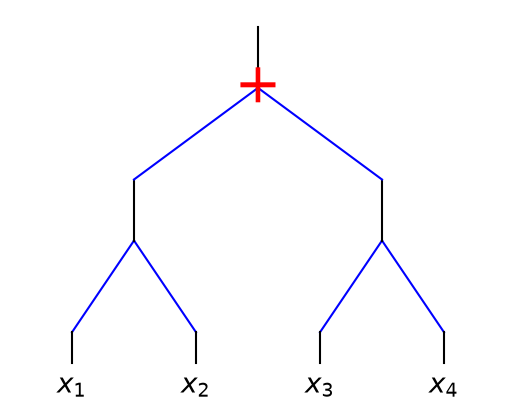

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.contrib.hypothesis import plot_tree

f = lambda x: (x[:,[0]]**2 + x[:,[1]]**2) ** 2 + (x[:,[2]]**2 + x[:,[3]]**2) ** 2
x = torch.rand(100,4) * 2 - 1
plot_tree(f, x)

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

train, test = create_dataset(f, n_var=4, device=device)
model = KANNetwork([4,5,5,1], seed=0, device=device)
history = fit(model, train, test, steps=100)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

cuda


train RMSE 0.0017091711614916703 test RMSE 0.004797404973987019


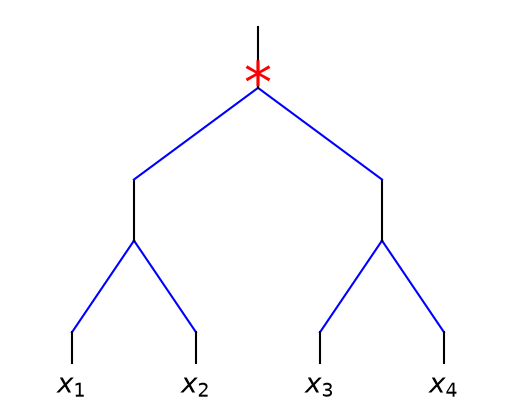

In [3]:
plot_tree(model, train['x'], sym_th=1e-2, sep_th=5e-1)